In [7]:
from pathlib import Path

import numpy as np
import pandas as pd

import geopandas as gpd
import osmnx as ox

import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, ConnectionPatch

# Folders
DATA_DIR = Path("../data/external")  
DATA_DIR.mkdir(exist_ok=True)
DATA_PROCESSED = Path("../data/processed")
DATA_PROCESSED.mkdir(exist_ok=True)
OUT = Path("../outputs")
OUT.mkdir(exist_ok=True)

# Variables
CRS_M = "EPSG:3416"  # Projected CRS for Austria (meters)

# Path important files
pbf_path = DATA_DIR / "austria-latest.osm.pbf"
austria_path = DATA_DIR / "austria_boundary.gpkg"
states_path = DATA_DIR / "austria_states.gpkg"
vienna_path = DATA_DIR / "BEZIRKSGRENZEOGD.zip"

ox.settings.use_cache = True
ox.settings.log_console = True

In [2]:
austria_limits = gpd.read_file(austria_path).to_crs(CRS_M)
austria_states = gpd.read_file(states_path).to_crs(CRS_M)
vienna_limits = gpd.read_file(vienna_path).to_crs(CRS_M)

In [3]:
pts_path = DATA_PROCESSED / "austria_recycling_points.gpkg"

if not pts_path.exists():
    pts = gpd.read_file(
        pbf_path,
        engine="pyogrio",
        sql="SELECT * FROM points WHERE other_tags LIKE '%\"amenity\"=>\"recycling\"%'",
        sql_dialect="OGRSQL",
    )
    pts.to_crs(CRS_M).to_file(pts_path, driver="GPKG")
else:
    pts = gpd.read_file(pts_path).to_crs(CRS_M)

In [4]:
poly_path = DATA_PROCESSED / "austria_recycling_polygons.gpkg"

if not poly_path.exists():
    poly = gpd.read_file(
        pbf_path,
        engine="pyogrio",
        sql="SELECT * FROM multipolygons WHERE amenity = 'recycling'",
        sql_dialect="OGRSQL",
    )
    poly["geometry"] = poly.geometry.representative_point()
    poly.to_crs(CRS_M).to_file(poly_path, driver="GPKG")
else:
    poly = gpd.read_file(poly_path).to_crs(CRS_M)

In [5]:
recycling = gpd.GeoDataFrame(
    pd.concat([pts, poly], ignore_index=True), geometry="geometry", crs=CRS_M
)

vienna_recycling = gpd.clip(recycling, vienna_limits)
vienna_recycling.head()

,osm_id,name,barrier,highway,ref,address,is_in,place,man_made,other_tags,...,historic,land_area,landuse,leisure,military,natural,office,shop,sport,tourism
10386,13037814249,NaN,NaN,None,NaN,None,None,None,None,"""access""=>""unknown"",""amenity""=>""recycling"",""op...",...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9793,12080282175,NaN,NaN,None,NaN,None,None,None,None,"""access""=>""yes"",""amenity""=>""recycling"",""operat...",...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9241,11143742916,NaN,NaN,None,NaN,None,None,None,None,"""amenity""=>""recycling"",""recycling:glass_bottle...",...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9242,11143742917,NaN,NaN,None,NaN,None,None,None,None,"""amenity""=>""recycling"",""recycling:clothes""=>""y...",...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6961,7465828675,NaN,NaN,None,NaN,None,None,None,None,"""amenity""=>""recycling"",""operator""=>""MA 48"",""op...",...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


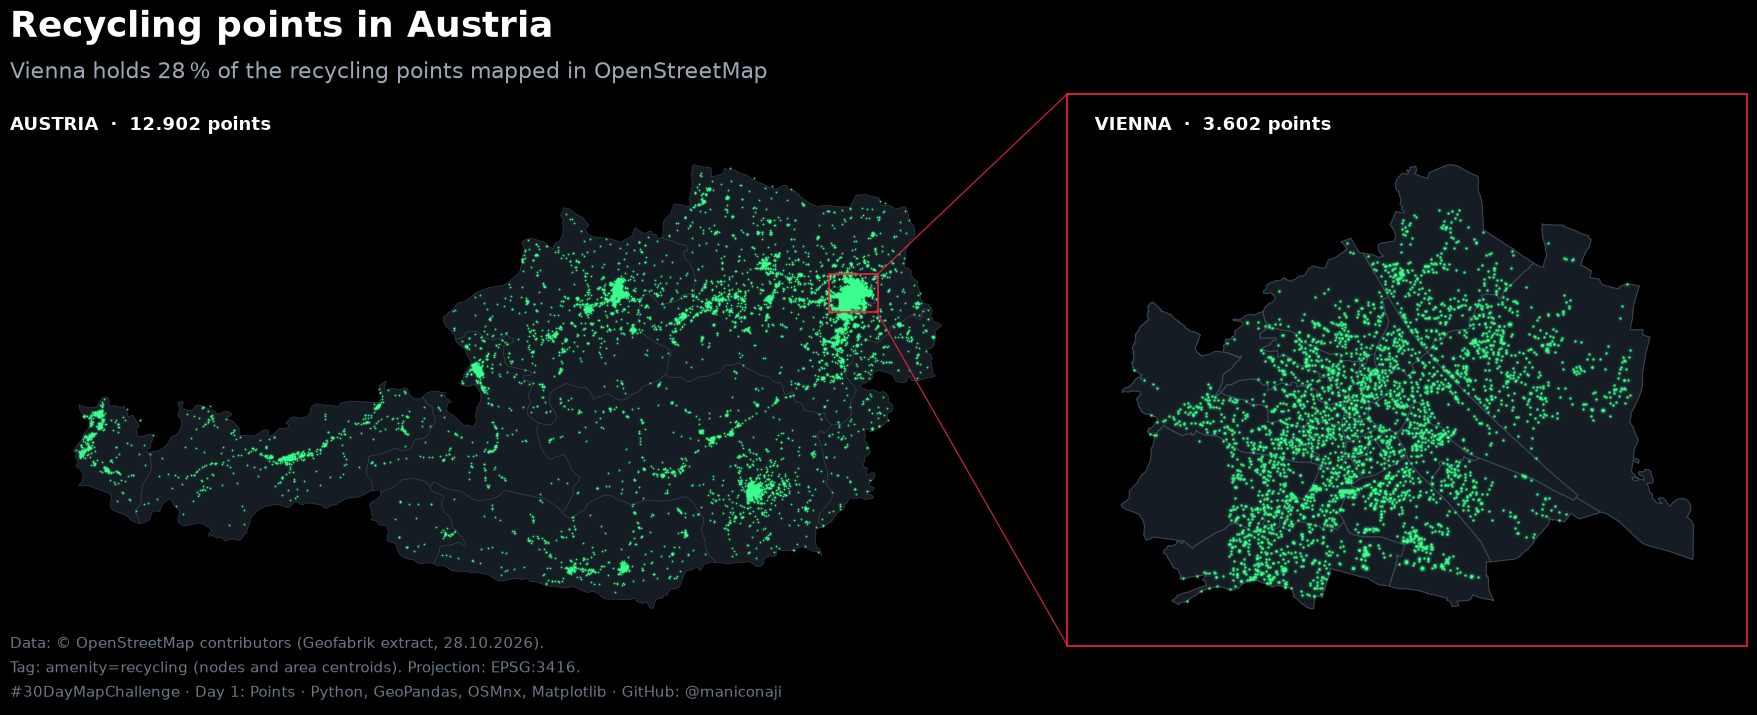

In [19]:
BG, LAND, EDGE, GLOW = "#000000", "#161c24", "#3a4655", "#3dff8f"
BOX = "#F0263C"   # red: highlights the zoom without competing with the green points

ax0, ay0, ax1, ay1 = austria_states.total_bounds
vx0, vy0, vx1, vy1 = vienna_limits.total_bounds
a_ratio = (ax1 - ax0) / (ay1 - ay0)
v_ratio = (vx1 - vx0) / (vy1 - vy0)

H = 5
W = H * (a_ratio + v_ratio) * 1.12

fig, (ax, ay) = plt.subplots(
    1, 2, figsize=(W, H + 2.4), facecolor=BG,
    gridspec_kw={"width_ratios": [a_ratio, v_ratio], "wspace": 0.09},
)
fig.subplots_adjust(left=0.02, right=0.97, top=0.78, bottom=0.12)

def glow(a, gdf, size, halo=1.0):
    kw = dict(color=GLOW, linewidth=0)
    gdf.plot(ax=a, markersize=size * 10, alpha=0.04 * halo, zorder=2, **kw)
    gdf.plot(ax=a, markersize=size * 3,  alpha=0.12 * halo, zorder=3, **kw)
    gdf.plot(ax=a, markersize=size,      alpha=0.90,        zorder=4, **kw)

# Austria
austria_states.plot(ax=ax, color=LAND, edgecolor=EDGE, linewidth=0.4, zorder=0)
glow(ax, recycling, size=1.5, halo=0.7)

# Vienna
vienna_limits.plot(ax=ay, color=LAND, edgecolor=EDGE, linewidth=0.8, zorder=0)
glow(ay, vienna_recycling, size=3, halo=1.0)

for a in (ax, ay):
    a.set_axis_off()

# Zoom box + connector lines
m = 0.04 * (vx1 - vx0)
ax.add_patch(
    Rectangle((vx0 - m, vy0 - m), (vx1 - vx0) + 2*m, (vy1 - vy0) + 2*m, fill=False, ec=BOX, lw=1.2, zorder=6))

# Frame around the Vienna panel (axes coordinates, slightly padded)
PAD_X, PAD_BOT, PAD_TOP = 0.04, 0.03, 0.10   # TOP leaves room for the label
frame = Rectangle(
    (-PAD_X, -PAD_BOT), 1 + 2 * PAD_X, 1 + PAD_BOT + PAD_TOP,
    transform=ay.transAxes, fill=False, ec=BOX, lw=1.2,
    clip_on=False, zorder=10,
)
ay.add_patch(frame)

for corner_data, corner_axes in [((vx1, vy1), (-PAD_X, 1 + PAD_TOP)), ((vx1, vy0), (-PAD_X, - PAD_BOT))]:
    fig.add_artist(ConnectionPatch(
        xyA=corner_data, coordsA=ax.transData,
        xyB=corner_axes, coordsB=ay.transAxes,
        color=BOX, lw=0.9, alpha=0.85,
    ))

def fmt(n):
    return f"{n:,}".replace(",", ".")

fig.canvas.draw()
bb = frame.get_window_extent().transformed(fig.transFigure.inverted())
y_lab = bb.y1 - 0.03

fig.text(
    0.02, y_lab, f"AUSTRIA  ·  {fmt(len(recycling))} points",
    color="white", fontsize=13, fontweight="bold", va="top")
fig.text(
    bb.x0 + 0.015, y_lab, f"VIENNA  ·  {fmt(len(vienna_recycling))} points",
    color="white", fontsize=13, fontweight="bold", va="top")

# Title and subtitle
fig.text(
    0.02, 0.96, "Recycling points in Austria",
    color="white", fontsize=26, fontweight="bold", va="top")

pct = len(vienna_recycling) / len(recycling) * 100
fig.text(
    0.02, 0.89,
    f"Vienna holds {pct:.0f}\u202f% of the recycling points mapped in OpenStreetMap",
    color="#9aa7b4", fontsize=16, va="top")

# Footer (three lines)
fig.text(
    0.02, 0.02,
    "Data: © OpenStreetMap contributors (Geofabrik extract, 28.10.2026).\n"
    f"Tag: amenity=recycling (nodes and area centroids). Projection: {CRS_M}.\n"
    "#30DayMapChallenge · Day 1: Points · Python, GeoPandas, OSMnx, Matplotlib · GitHub: @maniconaji",
    color="#6b7785", fontsize=11, va="bottom", linespacing=1.6,
)

plt.savefig(OUT / "day01_recycling_austria_vienna.png", dpi=300, facecolor=BG, bbox_inches=None)
plt.show()